# 0.1 Root Finding in One Dimension

## Setup

In [49]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [50]:
from collections.abc import Callable
from typing import NamedTuple
import numpy.typing as npt

In [51]:
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.engine": 'latex',
    "text.latex.preamble": r'\usepackage{amsmath}\usepackage{mathtools}\usepackage{permute}\usepackage[notrig]{physics}\input{macros.tex}',
})

In [52]:
plt.rcParams.update({
    "figure.dpi": 200,
    "savefig.dpi": 1200,
    "savefig.transparent": True,
    "savefig.bbox": 'tight'
})

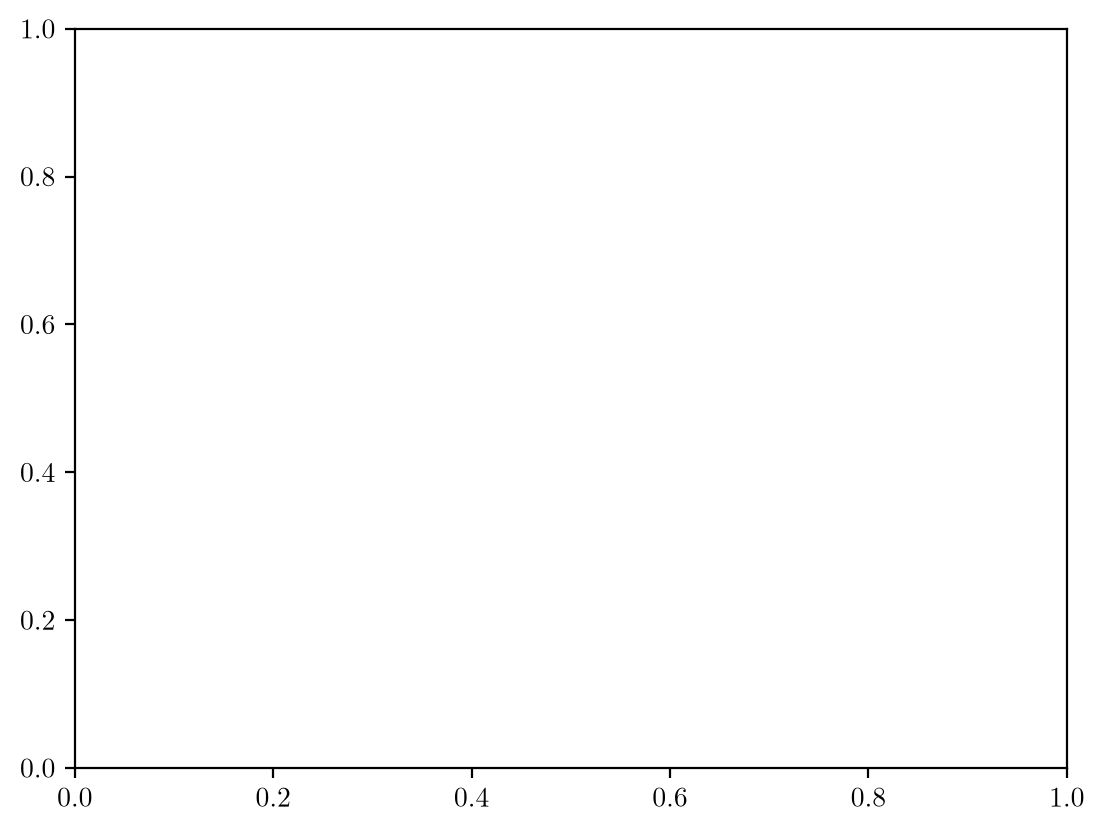

In [53]:
fig, ax = plt.subplots()

## Question 1

In [54]:
x: npt.ArrayLike = np.arange(-4.0, -1.0, 0.01)
y1: npt.ArrayLike = 2 * x + 5
y2: npt.ArrayLike = 3 * np.sin(x)

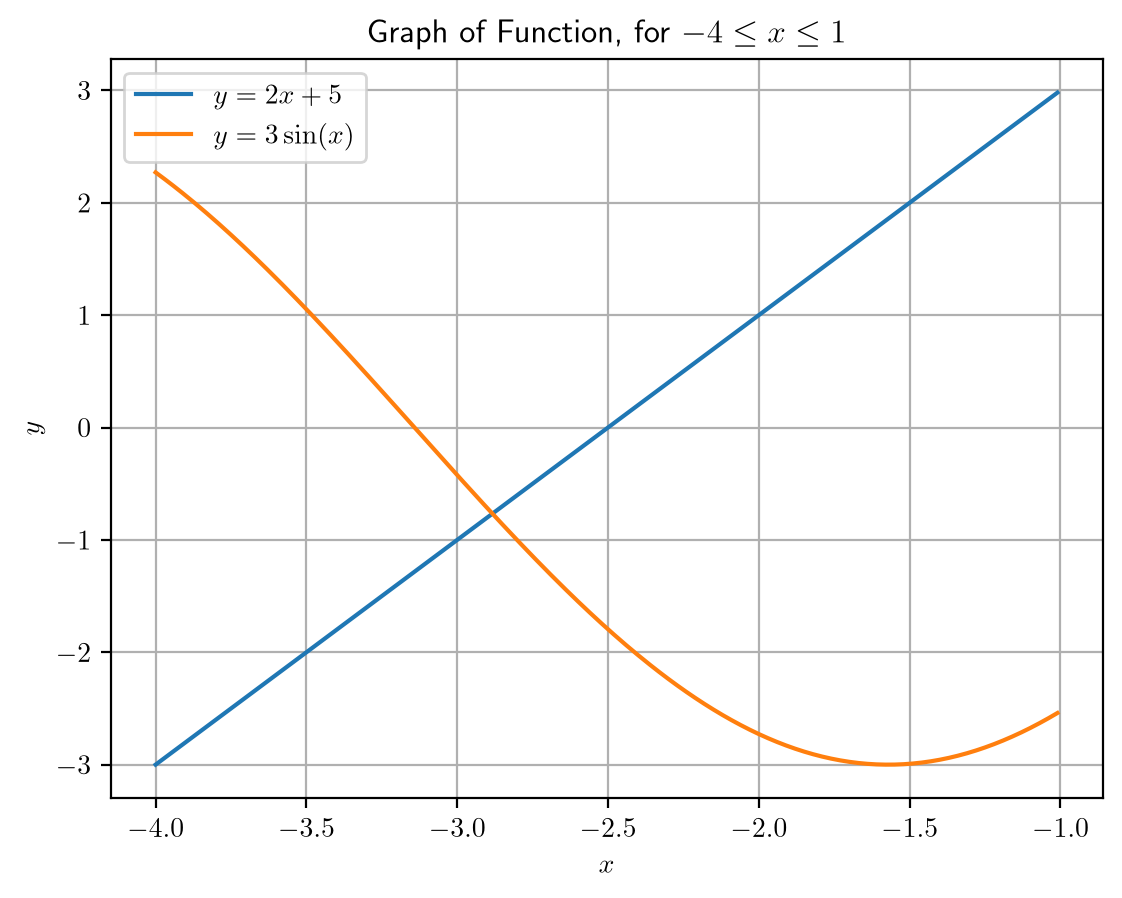

In [55]:
ax.clear()

ax.plot(x, y1, label=r'\(y = 2x + 5\)')
ax.plot(x, y2, label=r'\(y = 3 \sin \pqty{x}\)')

ax.set(xlabel=r'\(x\)',
       ylabel=r'\(y\)',
       title=r'Graph of Function, for \(-4 \leq x \leq 1\)')
ax.grid()
ax.legend()

fig.savefig("../fig/question-1.png")

fig

## Programming Task: Binary Search

In [56]:
F = lambda x: 2 * x - 3 * np.sin(x) + 5

In [57]:
class BinarySearchResult(NamedTuple):
    iteration_count: int # number of iterations
    root_estimate: float # estimate of root
    error: float # truncation error

In [58]:
def binary_search(
    function: Callable[[float], float], # function for binary search
    left_endpoint: float, # starting left-endpoint
    right_endpoint: float, # starting right-endpoint
    truncation_error: float = 5e-6, # truncation error
    max_iteration: int = 1000 # max iterations
) -> BinarySearchResult:
    iteration: int = 0

    if function(right_endpoint) == 0:
        return BinarySearchResult(0, right_endpoint, 0)
    
    if function(left_endpoint) == 0:
        return BinarySearchResult(0, right_endpoint, 0)

    incr: int

    if function(right_endpoint) > 0 and function(left_endpoint) < 0: # increasing
        incr = 1
    elif function(right_endpoint) < 0 and function(left_endpoint) > 0: # decreasing
        incr = -1
    else:
        raise ValueError
    
    while (np.abs(right_endpoint - left_endpoint) >= 2 * truncation_error) and (iteration < max_iteration):
        iteration += 1

        midpoint: float = (left_endpoint + right_endpoint) / 2

        if function(midpoint) * incr > 0: # on the left
            right_endpoint = midpoint
        elif function(midpoint) * incr < 0: # on the right
            left_endpoint = midpoint
        else: # = 0
            return BinarySearchResult(iteration, midpoint, 0)

    return BinarySearchResult(iteration, (right_endpoint + left_endpoint) / 2, np.abs(right_endpoint - left_endpoint) / 2)

In [59]:
print(binary_search(F, -3, -2))
print(binary_search(F, -np.pi, 0))
print(binary_search(F, -10, 10))

print(binary_search(F, -4, -1))

BinarySearchResult(iteration_count=17, root_estimate=-2.8832359313964844, error=np.float64(3.814697265625e-06))
BinarySearchResult(iteration_count=19, root_estimate=-2.883239729136342, error=np.float64(2.9960562262232315e-06))
BinarySearchResult(iteration_count=21, root_estimate=-2.8832387924194336, error=np.float64(4.76837158203125e-06))
BinarySearchResult(iteration_count=19, root_estimate=-2.883236885070801, error=np.float64(2.86102294921875e-06))


## What is the Root Itself? [To the best of Float]

In [60]:
result: BinarySearchResult = binary_search(F, -3, -2, truncation_error=0)
x_ast: float = result.root_estimate
print(result.error, x_ast)

0 -2.8832368725582835


## Programming Task: Fixed-Point Iteration

In [61]:
class IterationProcess(NamedTuple):
    iteration: int # current iteration
    current_root_estimate: float # current value

In [62]:
def fixed_point_iteration(
    function: Callable[[float], float], # function for fixed point iteration
    x: float, # starting value
    term_difference: float = 1e-5, # end term difference
    max_iteration: int = 1000 # max iterations
) -> list[IterationProcess]:
    iteration: int = 0
    result: list[IterationProcess] = [IterationProcess(iteration, x)]

    while (iteration == 0 or
           np.abs(result[-1].current_root_estimate - result[-2].current_root_estimate) >= term_difference) and (iteration < max_iteration):
        iteration += 1

        x = function(x)
        result.append(IterationProcess(iteration, x))

    return result

## Question 3

In [63]:
fk = lambda x, k: (3 * np.sin(x) + k * x - 5) / (2 + k)
dfk = lambda x, k: (3 * np.cos(x) + k) / (2 + k)

In [64]:
def fixed_point_iteration_coordinates(root_estimate: pd.DataFrame,
                             function: Callable[[float], float],
                             length: int=-1) -> pd.DataFrame: # convert iteration process to coordinates
    if length == -1:
        length = len(root_estimate.index)
    iteration_process = pd.DataFrame(index=np.arange(0, 2 * length), columns=["x", "y"])

    for i in range(length):
        x: float = root_estimate.current_root_estimate[i]

        if i != 0:
            iteration_process.loc[2 * i] = (x, x)
            
        iteration_process.loc[2 * i + 1] = (x, function(x))

    return iteration_process

In [65]:
def plot_fixed_point_iteration_graph(function,
                         root_estimate: pd.DataFrame,
                         x: npt.ArrayLike,
                         initial_guess: float,
                         root: float,
                         title: str) -> None:
    iteration_process: pd.DataFrame = fixed_point_iteration_coordinates(root_estimate, function)
    y: npt.ArrayLike = function(x)

    ax.clear()

    ax.plot(x, x, label=r'\(y = x\)')
    ax.plot(x, y, label=r'\(y = f\pqty{x}\)')

    ax.plot(initial_guess, function(initial_guess), marker='+', color='g')
    ax.plot(iteration_process.x,
            iteration_process.y,
            label='Iteration Process',
            marker=',', linewidth=0.5, color='g')

    ax.plot(root, root, marker='+', color='r')

    ax.set(xlabel=r'\(x\)',
        ylabel=r'\(y\)',
        title=title)
    ax.grid()
    ax.legend()

In [66]:
def truncation_errors(function,
                      root_estimate: pd.DataFrame) -> pd.DataFrame:
    truncation_errors: pd.DataFrame = pd.DataFrame(root_estimate).drop(columns=["iteration"])

    truncation_errors["function_value"] = function(truncation_errors["current_root_estimate"])
    truncation_errors["truncation_error"] = truncation_errors["current_root_estimate"] - x_ast
    truncation_errors["truncation_ratio"] = truncation_errors["truncation_error"] / truncation_errors["truncation_error"].shift(1)

    
    return truncation_errors

### (i): non-convergence

In [67]:
f = lambda x: fk(x, 0)
df = lambda x: dfk(x, 0)

In [68]:
root_estimate = pd.DataFrame(fixed_point_iteration(f, -2, 1e-5, 10))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-3.863946
2,2,-1.508272
3,3,-3.997069
4,4,-1.367675
5,5,-3.969163
6,6,-1.395566
7,7,-3.977030
8,8,-1.387615
9,9,-3.974904


In [69]:
data: pd.DataFrame = truncation_errors(f, root_estimate)
data.to_csv('../data/question-3-i-data.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,-2.000000,-3.863946,0.883237,NaN
1,-3.863946,-1.508272,-0.980709,-1.110358
2,-1.508272,-3.997069,1.374965,-1.402011
3,-3.997069,-1.367675,-1.113832,-0.810080
4,-1.367675,-3.969163,1.515562,-1.360674
5,-3.969163,-1.395566,-1.085926,-0.716517
6,-1.395566,-3.977030,1.487671,-1.369956
7,-3.977030,-1.387615,-1.093793,-0.735239
8,-1.387615,-3.974904,1.495622,-1.367372
9,-3.974904,-1.389757,-1.091667,-0.729909


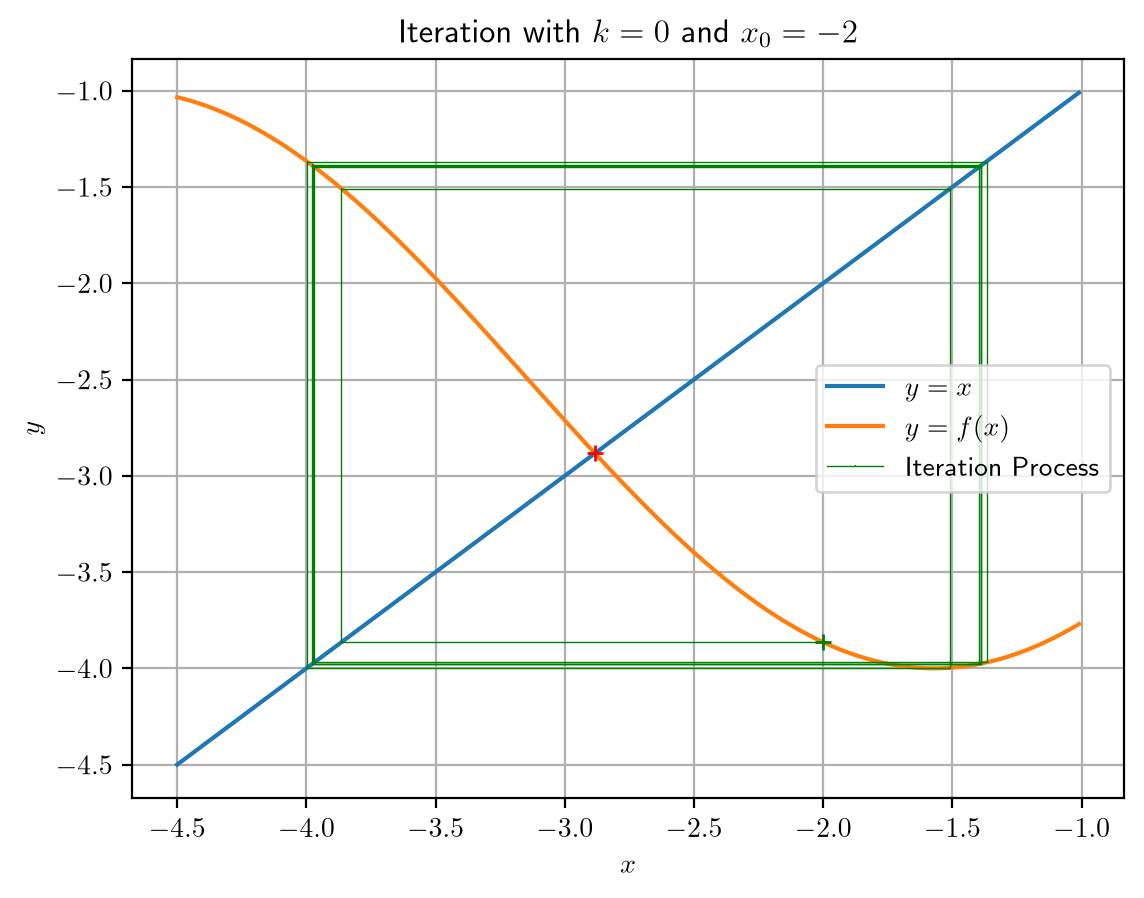

In [70]:
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(-4.5, -1.0, 0.01),
                     -2,
                     x_ast,
                     r'Iteration with \(k = 0\) and \(x_0 = -2\)')

fig.savefig("../fig/question-3-i.png")
fig

In [71]:
df(x_ast)

np.float64(-1.450217052551702)

### (iii): Monotonic Convergence

In [72]:
dfk(x_ast, 3)

np.float64(0.019913178979319213)

In [73]:
f = lambda x: fk(x, 3)
root_estimate = pd.DataFrame(fixed_point_iteration(f, -2, 1e-5, 20))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-2.745578
2,2,-2.878794
3,3,-2.883147
4,4,-2.883235
5,5,-2.883237


In [74]:
data: pd.DataFrame = truncation_errors(f, root_estimate)
data.to_csv('../data/question-3-iii-data-1.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,-2.000000,-2.745578,8.832369e-01,NaN
1,-2.745578,-2.878794,1.376584e-01,0.155857
2,-2.878794,-2.883147,4.443344e-03,0.032278
3,-2.883147,-2.883235,9.000286e-05,0.020256
4,-2.883235,-2.883237,1.792864e-06,0.019920
5,-2.883237,-2.883237,3.570187e-08,0.019913


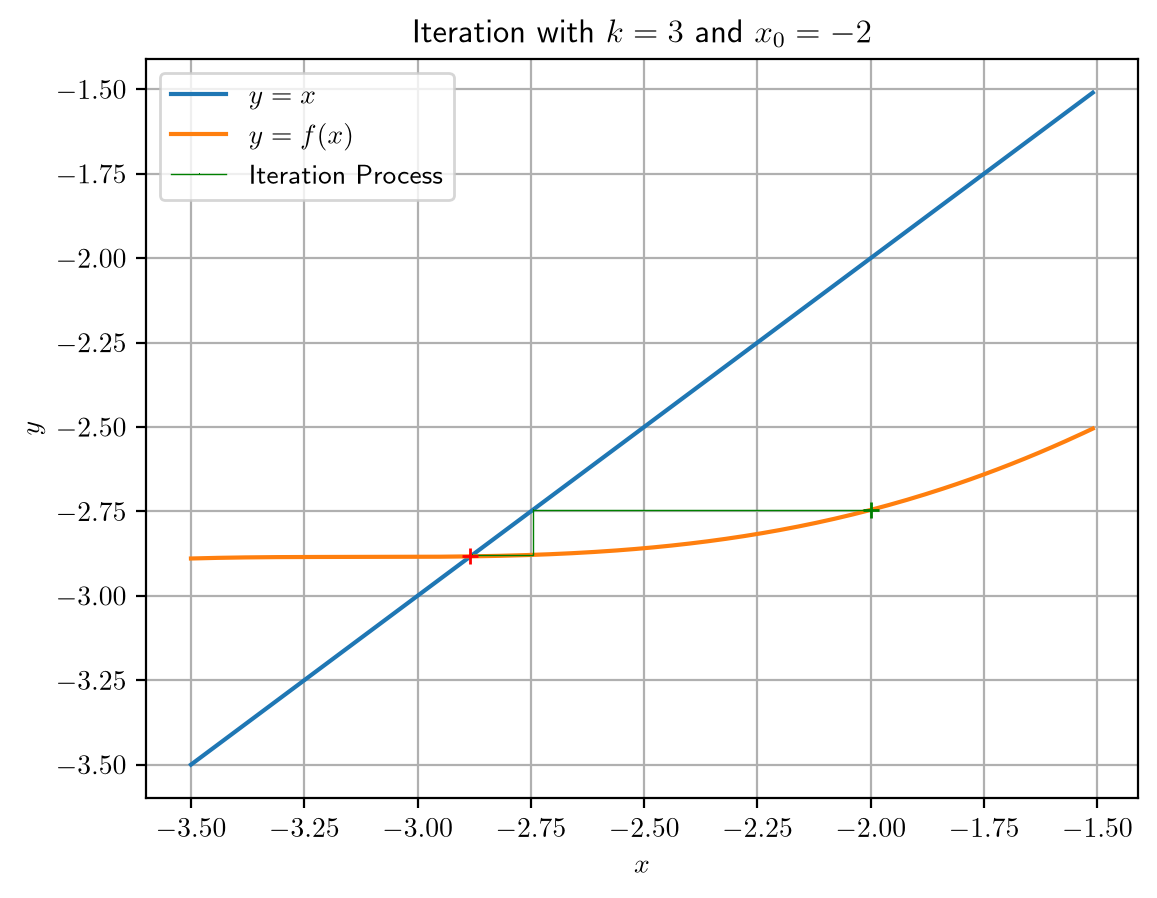

In [75]:
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(-3.5, -1.5, 0.01),
                     -2,
                     x_ast,
                     r'Iteration with \(k = 3\) and \(x_0 = -2\)')

fig.savefig('../fig/question-3-iii-1.png')
fig

### (iii): Oscillatory Convergence

In [76]:
dfk(x_ast, 1)

np.float64(-0.633478035034468)

In [77]:
f = lambda x: fk(x, 1)
root_estimate = pd.DataFrame(fixed_point_iteration(f, -2, 1e-5, 20))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-3.242631
2,2,-2.646677
3,3,-3.023850
4,4,-2.792088
5,5,-2.939795
6,6,-2.847029
7,7,-2.905999
8,8,-2.868753
9,9,-2.892384


In [78]:
data: pd.DataFrame = truncation_errors(f, root_estimate)
data.to_csv('../data/question-3-iii-data-2.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,-2.000000,-3.242631,0.883237,NaN
1,-3.242631,-2.646677,-0.359394,-0.406905
2,-2.646677,-3.023850,0.236560,-0.658218
3,-3.023850,-2.792088,-0.140613,-0.594407
4,-2.792088,-2.939795,0.091149,-0.648228
5,-2.939795,-2.847029,-0.056558,-0.620504
6,-2.847029,-2.905999,0.036208,-0.640186
7,-2.905999,-2.868753,-0.022762,-0.628642
8,-2.868753,-2.892384,0.014483,-0.636302
9,-2.892384,-2.877431,-0.009148,-0.631594


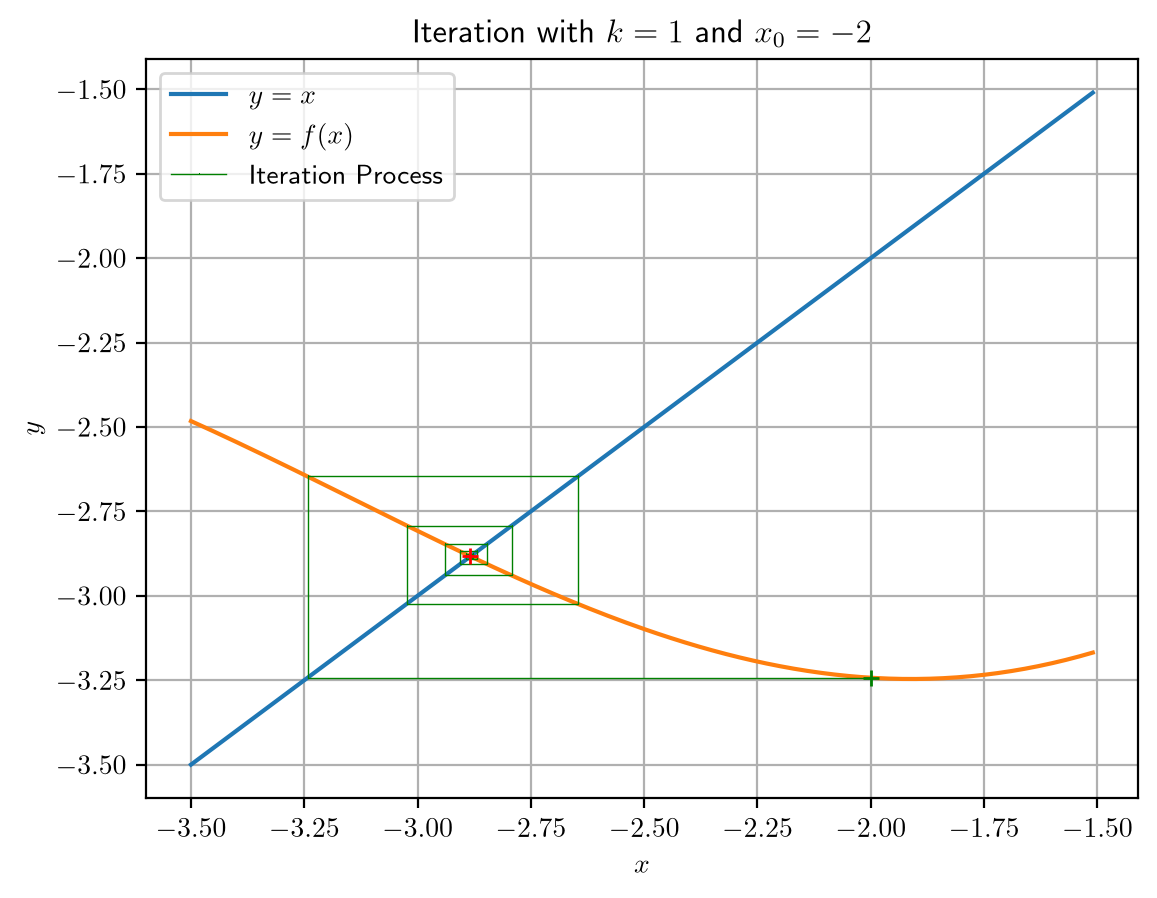

In [79]:
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(-3.5, -1.5, 0.01),
                     -2,
                     x_ast,
                     r'Iteration with \(k = 1\) and \(x_0 = -2\)')

fig.savefig('../fig/question-3-iii-2.png')
fig

### (iv): slow convergence

In [80]:
f = lambda x: fk(x, 16)
df = lambda x: dfk(x, 16)

root_estimate = pd.DataFrame(fixed_point_iteration(f, -2, 1e-5, 50))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-2.207105
2,2,-2.373698
3,3,-2.503502
4,4,-2.602390
5,5,-2.676589
6,6,-2.731705
7,7,-2.772378
8,8,-2.802261
9,9,-2.824153


In [81]:
data: pd.DataFrame = truncation_errors(f, root_estimate)
data.to_csv('../data/question-3-iv-data.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,-2.000000,-2.207105,0.883237,NaN
1,-2.207105,-2.373698,0.676132,0.765516
2,-2.373698,-2.503502,0.509539,0.753609
3,-2.503502,-2.602390,0.379735,0.745252
4,-2.602390,-2.676589,0.280847,0.739587
5,-2.676589,-2.731705,0.206648,0.735804
6,-2.731705,-2.772378,0.151531,0.733282
7,-2.772378,-2.802261,0.110859,0.731590
8,-2.802261,-2.824153,0.080976,0.730441
9,-2.824153,-2.840158,0.059084,0.729653


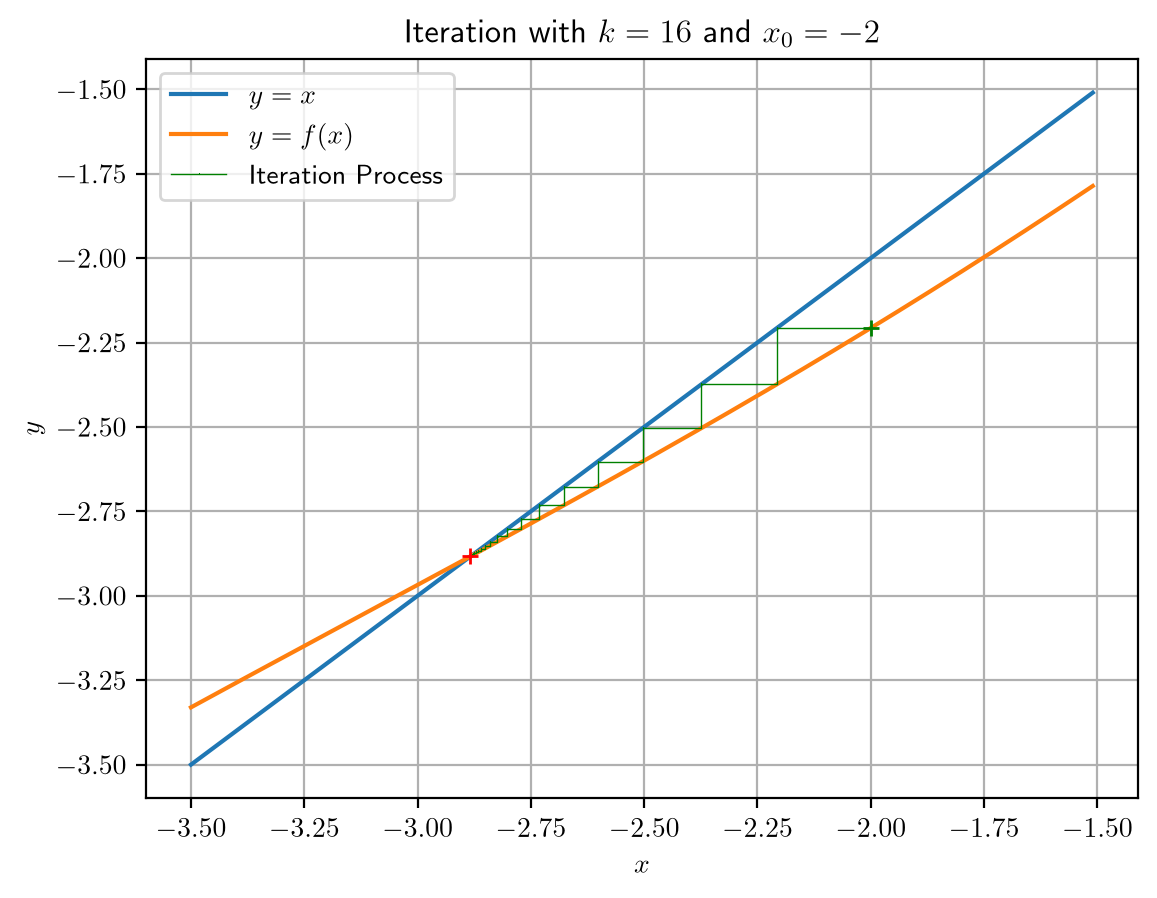

In [82]:
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(-3.5, -1.5, 0.01),
                     -2,
                     x_ast,
                     r'Iteration with \(k = 16\) and \(x_0 = -2\)')

fig.savefig('../fig/question-3-iv.png')
fig

In [83]:
root_estimate.iloc[-1].current_root_estimate - x_ast

np.float64(2.1084511679703155e-05)

In [84]:
df(-3), df(-2)

(np.float64(0.7238901394554813), np.float64(0.8195310827976985))

In [85]:
0.75 * (0.72 ** 34), 1 * (0.82 ** 34)

(1.0577088594564252e-05, 0.0011740077965196548)

###  (v): rate of convergence

## Question 4

In [86]:
f = lambda x: (- np.pow(x, 3) + 8.5 * np.pow(x, 2) + 8) / 20

In [87]:
root_estimate = pd.DataFrame(fixed_point_iteration(f, 5, 1e-5, 1000))
root_estimate

,iteration,current_root_estimate
0,0,5.000000
1,1,4.775000
2,2,4.646616
3,3,4.559929
4,4,4.496285
...,...,...
736,736,4.007574
737,737,4.007564
738,738,4.007554
739,739,4.007544


In [88]:
data: pd.DataFrame = truncation_errors(f, root_estimate)
data.to_csv('../data/question-4-data.csv')
data

,current_root_estimate,function_value,truncation_error,truncation_ratio
0,5.000000,4.775000,7.883237,NaN
1,4.775000,4.646616,7.658237,0.971458
2,4.646616,4.559929,7.529853,0.983236
3,4.559929,4.496285,7.443166,0.988487
4,4.496285,4.447071,7.379522,0.991449
...,...,...,...,...
736,4.007574,4.007564,6.890811,0.999999
737,4.007564,4.007554,6.890801,0.999999
738,4.007554,4.007544,6.890791,0.999999
739,4.007544,4.007534,6.890781,0.999999


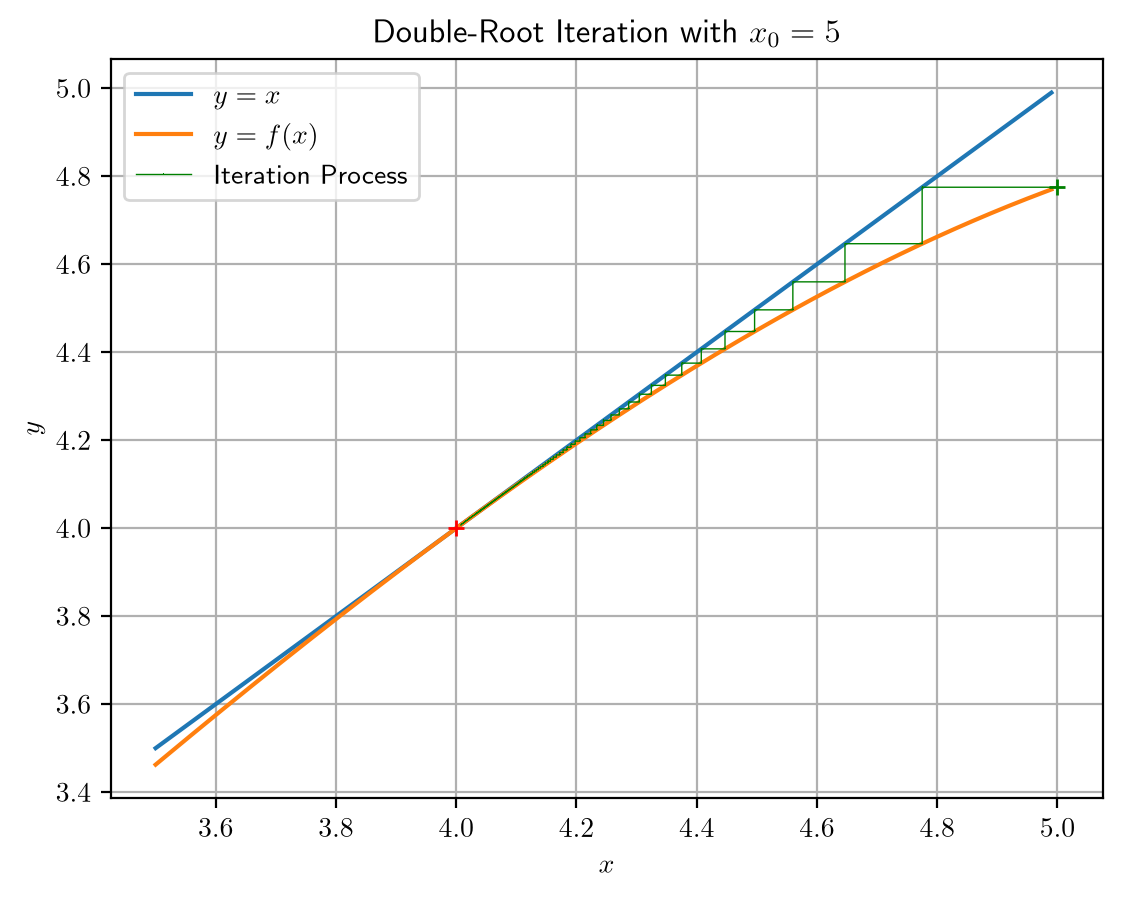

In [89]:
plot_fixed_point_iteration_graph(f,
                     root_estimate,
                     np.arange(3.5, 5, 0.01),
                     5,
                     4,
                     r'Double-Root Iteration with \(x_0 = 5\)')

fig.savefig('../fig/question-4.png')
fig

## Programming Task: Newton-Raphson

In [90]:
def newton_raphson_iteration(
    function: Callable[[float], float], # function for newton-raphson iteration
    derivative: Callable[[float], float], # derivative for newton-raphson iteration
    x: float, # starting value
    term_difference: float = 1e-20, # end term difference
    max_iteration: int = 1000 # max iterations
) -> list[IterationProcess]:
    return fixed_point_iteration(lambda x: x - function(x) / derivative(x), x, term_difference=term_difference, max_iteration=max_iteration)

## Question 5

### Equation 4

In [91]:
f = lambda x: 2 * x - 3 * np.sin(x) + 5
df = lambda x: 2 - 3 * np.cos(x)

In [92]:
newton_raphson_iteration(f, df, -10, max_iteration=1000)

[IterationProcess(iteration=0, current_root_estimate=-10),
 IterationProcess(iteration=1, current_root_estimate=np.float64(-6.318071012236455)),
 IterationProcess(iteration=2, current_root_estimate=np.float64(-13.863349798502137)),
 IterationProcess(iteration=3, current_root_estimate=np.float64(2.8248061020398456)),
 IterationProcess(iteration=4, current_root_estimate=np.float64(0.8219982359480231)),
 IterationProcess(iteration=5, current_root_estimate=np.float64(105.99792750405283)),
 IterationProcess(iteration=6, current_root_estimate=np.float64(4095.887884971531)),
 IterationProcess(iteration=7, current_root_estimate=np.float64(45663.073711082376)),
 IterationProcess(iteration=8, current_root_estimate=np.float64(27393.542186933715)),
 IterationProcess(iteration=9, current_root_estimate=np.float64(-44429.186168641216)),
 IterationProcess(iteration=10, current_root_estimate=np.float64(-745732.7526323213)),
 IterationProcess(iteration=11, current_root_estimate=np.float64(-2542281.08408

In [93]:
root_estimate = pd.DataFrame(newton_raphson_iteration(f, df, -2))
root_estimate

,iteration,current_root_estimate
0,0,-2.000000
1,1,-3.147594
2,2,-2.884953
3,3,-2.883237
4,4,-2.883237
5,5,-2.883237
6,6,-2.883237


In [94]:
intermediate_data: pd.DataFrame = pd.DataFrame(root_estimate).drop(columns=["iteration"])

intermediate_data["function_value"] = f(intermediate_data["current_root_estimate"])
intermediate_data["derivative_value"] = df(intermediate_data["current_root_estimate"])
intermediate_data["truncation_error"] = intermediate_data["current_root_estimate"] - x_ast
intermediate_data["truncation_ratio"] = intermediate_data["truncation_error"] / intermediate_data["truncation_error"].shift(1)
intermediate_data["truncation_ratio_squared"] = intermediate_data["truncation_error"] / np.pow(intermediate_data["truncation_error"].shift(1), 2)

intermediate_data

,current_root_estimate,function_value,derivative_value,truncation_error,truncation_ratio,truncation_ratio_squared
0,-2.000000,3.727892e+00,3.248441,8.832369e-01,NaN,NaN
1,-3.147594,-1.313194e+00,4.999946,-2.643576e-01,-2.993054e-01,-0.338873
2,-2.884953,-8.409796e-03,4.901745,-1.715903e-03,6.490841e-03,-0.024553
3,-2.883237,-1.123187e-06,4.900434,-2.292016e-07,1.335749e-04,-0.077845
4,-2.883237,-1.953993e-14,4.900434,-3.996803e-15,1.743794e-08,-0.076081
5,-2.883237,0.000000e+00,4.900434,0.000000e+00,-0.000000e+00,0.000000
6,-2.883237,0.000000e+00,4.900434,0.000000e+00,NaN,NaN


In [95]:
root_estimate = pd.DataFrame(newton_raphson_iteration(f, df, -6))
root_estimate

,iteration,current_root_estimate
0,0,-6.000000
1,1,-14.901931
2,2,-9.349154
3,3,-6.650195
4,4,-15.677677
...,...,...
139,139,-2.877015
140,140,-2.883240
141,141,-2.883237
142,142,-2.883237


In [96]:
intermediate_data: pd.DataFrame = pd.DataFrame(root_estimate).drop(columns=["iteration"])

intermediate_data["function_value"] = f(intermediate_data["current_root_estimate"])
intermediate_data["derivative_value"] = df(intermediate_data["current_root_estimate"])
intermediate_data["truncation_error"] = intermediate_data["current_root_estimate"] - x_ast
intermediate_data["truncation_ratio"] = intermediate_data["truncation_error"] / intermediate_data["truncation_error"].shift(1)
intermediate_data["truncation_ratio_squared"] = intermediate_data["truncation_error"] / np.pow(intermediate_data["truncation_error"], 2).shift(1)

intermediate_data

,current_root_estimate,function_value,derivative_value,truncation_error,truncation_ratio,truncation_ratio_squared
0,-6.000000,-7.838246e+00,-0.880511,-3.116763e+00,NaN,NaN
1,-14.901931,-2.263922e+01,4.077099,-1.201869e+01,3.856146e+00,-1.237228
2,-9.349154,-1.347165e+01,4.991426,-6.465917e+00,5.379883e-01,-0.044763
3,-6.650195,-7.223912e+00,-0.800213,-3.766958e+00,5.825869e-01,-0.090101
4,-15.677677,-2.626451e+01,4.998624,-1.279444e+01,3.396491e+00,-0.901654
...,...,...,...,...,...,...
139,-2.877015,3.047704e-02,4.895609,6.222306e-03,-1.227164e-02,0.024202
140,-2.883240,-1.508544e-05,4.900436,-3.078388e-06,-4.947343e-04,-0.079510
141,-2.883237,-3.632650e-12,4.900434,-7.411849e-13,2.407704e-07,-0.078213
142,-2.883237,0.000000e+00,4.900434,0.000000e+00,-0.000000e+00,0.000000
